# One-stage anchor-based detector: RetinaNet
Same protocol as the two-stage notebook: same splits, experiment subsets, resolution, optimizer, schedule and metrics.

## Setup

In [1]:
from google.colab import auth
from google.colab import userdata
import requests
import json
import subprocess
auth.authenticate_user()
email = subprocess.getoutput("gcloud config get-value account")
print(f"Current Google User: {email}")

DRIVE_ROOT = '/content/drive/MyDrive/datasets/hw2_train-s3_val-s3/' if email.startswith('kopach') else \
              '/content/drive/MyDrive/hw2_train-s3_val-s3'

Current Google User: ruzhylopv@gmail.com


In [2]:
!pip install -q ultralytics pycocotools

In [11]:
import shutil
from pathlib import Path
from google.colab import drive
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import pandas as pd
import yaml
import numpy as np
import math, time, json, random
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
from torchvision.ops import box_iou, sigmoid_focal_loss
from torchvision.models.detection import (retinanet_resnet50_fpn_v2, RetinaNet_ResNet50_FPN_V2_Weights,
                                          fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights)
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator
import torchvision.transforms.functional as TF
from tqdm.auto import tqdm
from pycocotools.cocoeval import COCOeval
from pycocotools.coco import COCO
from sklearn.cluster import KMeans

drive.mount('/content/drive', force_remount=True)
ROOT = Path(DRIVE_ROOT)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU - turn on the GPU runtime')

OUT = Path('/content/drive/MyDrive/hw2_runs/retinanet')
OUT.mkdir(parents=True, exist_ok=True)
FRCNN_OUT = Path('/content/drive/MyDrive/hw2_runs/frcnn')  # tuned two-stage results, used for the comparison

Mounted at /content/drive
Device: Tesla T4


In [17]:
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [5]:
EPOCHS = 6
EXP_EPOCHS = 2
EXP_TRAIN_IMAGES = 2000
EXP_VAL_IMAGES = 500

BATCH_SIZE = 2
LR = 0.005              # same as Faster R-CNN; if the loss goes NaN, use 0.0025 and say so in the report
MIN_SIZE, MAX_SIZE = 1024, 1824
MAX_DET = 300
SCORE_THRESH = 0.01

names = yaml.safe_load(open(ROOT / 'train' / 'data.yaml'))['names']
names = [names[k] for k in sorted(names)] if isinstance(names, dict) else names
NUM_CLASSES = len(names)

## Data (same as the two-stage notebook)

In [6]:
class CocoFrames(Dataset):
    def __init__(self, split, limit=None, augment=False):
        self.coco = COCO(str(ROOT / split / 'annotations_coco.json'))
        self.augment = augment
        anns = self.coco.dataset['annotations']
        good = [a for a in anns if a['category_id'] in self.coco.cats and a['bbox'][2] > 0 and a['bbox'][3] > 0]
        for a in good:
            a.setdefault('iscrowd', 0)
            a.setdefault('area', a['bbox'][2] * a['bbox'][3])
        self.coco.dataset['annotations'] = good
        self.coco.createIndex()
        for self.folder in [ROOT / split, ROOT / split / 'images']:
            self.ids = [i for i, im in sorted(self.coco.imgs.items()) if (self.folder / im['file_name']).exists()]
            if self.ids:
                break
        assert self.ids, f'No images from the {split} json were found on disk'
        total = len(self.ids)
        if limit and limit < total:
            self.ids = [self.ids[k] for k in np.linspace(0, total - 1, limit).astype(int)]
        cats = sorted(self.coco.cats.values(), key=lambda c: c['id'])
        if all(c['name'] in names for c in cats):
            self.cat2cls = {c['id']: names.index(c['name']) for c in cats}
        else:
            print('WARNING: json category names differ from data.yaml, matching them by order')
            self.cat2cls = {c['id']: k for k, c in enumerate(cats)}
        print(f'{split}: using {len(self.ids):,} frames ({len(self.coco.imgs):,} in json, {total:,} on disk), '
              f'dropped {len(anns) - len(good):,} bad annotations')

    def __len__(self):
        return len(self.ids)

    def boxes_and_labels(self, image_id):
        boxes, labels = [], []
        for a in self.coco.imgToAnns[image_id]:
            x, y, w, h = a['bbox']
            if not a['iscrowd']:
                boxes.append([x, y, x + w, y + h])
                labels.append(self.cat2cls[a['category_id']] + 1)
        return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), torch.tensor(labels, dtype=torch.int64)

    def __getitem__(self, idx):
        image_id = self.ids[idx]
        image = TF.to_tensor(Image.open(self.folder / self.coco.imgs[image_id]['file_name']).convert('RGB'))
        boxes, labels = self.boxes_and_labels(image_id)
        if self.augment and torch.rand(1) < 0.5:
            image = image.flip(-1)
            boxes[:, [0, 2]] = image.shape[-1] - boxes[:, [2, 0]]
        return image, {'boxes': boxes, 'labels': labels, 'image_id': image_id}


def collate(batch):
    return tuple(zip(*batch))


train_ds = CocoFrames('train', augment=True)
val_ds = CocoFrames('val')
exp_train = CocoFrames('train', limit=EXP_TRAIN_IMAGES, augment=True)  # same subsets as the Faster R-CNN study
exp_val = CocoFrames('val', limit=EXP_VAL_IMAGES)
print(NUM_CLASSES, 'classes:', names)

loading annotations into memory...
Done (t=12.53s)
creating index...
index created!
creating index...
index created!
train: using 7,514 frames (24,201 in json, 7,514 on disk), dropped 0 bad annotations
loading annotations into memory...
Done (t=1.94s)
creating index...
index created!
creating index...
index created!
val: using 922 frames (2,846 in json, 922 on disk), dropped 0 bad annotations
loading annotations into memory...
Done (t=7.15s)
creating index...
index created!
creating index...
index created!
train: using 2,000 frames (24,201 in json, 7,810 on disk), dropped 0 bad annotations
loading annotations into memory...
Done (t=0.65s)
creating index...
index created!
creating index...
index created!
val: using 500 frames (2,846 in json, 936 on disk), dropped 0 bad annotations
8 classes: ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']


## Anchor configuration from the data
Object sizes measured after the resize the model applies, and aspect-ratio clusters (YOLOv2-style k-means).

1,105,516 training boxes, size sqrt(w*h) in resized pixels:
count    1105516.0
mean          52.5
std           34.2
min            5.2
5%            19.3
25%           30.7
50%           43.2
75%           62.3
95%          118.9
max          672.2
dtype: float64
  under  8px: 0.0%
  under 16px: 2.2%
  under 32px: 27.6%
  under 64px: 76.4%
k-means aspect ratios (h/w): (0.5, 1.02, 2.01)


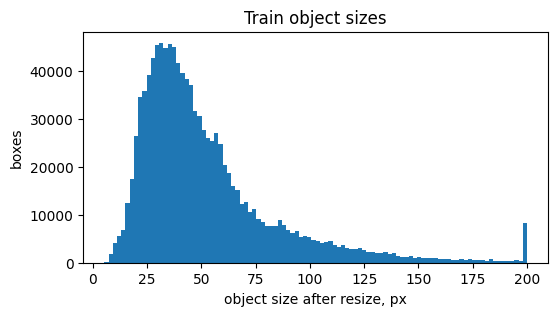

In [7]:
def resize_scale(w, h):  # the same rule torchvision's transform uses
    return min(MIN_SIZE / min(w, h), MAX_SIZE / max(w, h))

wh = []
for a in train_ds.coco.dataset['annotations']:
    if a['iscrowd'] or a['image_id'] not in train_ds.coco.imgs:
        continue
    im = train_ds.coco.imgs[a['image_id']]
    s = resize_scale(im['width'], im['height'])
    wh.append((a['bbox'][2] * s, a['bbox'][3] * s))
wh = np.array(wh)
side = np.sqrt(wh.prod(1))

print(f'{len(wh):,} training boxes, size sqrt(w*h) in resized pixels:')
print(pd.Series(side).describe(percentiles=[.05, .25, .5, .75, .95]).round(1))
for t in (8, 16, 32, 64):
    print(f'  under {t:>2}px: {(side < t).mean():.1%}')

# Aspect ratio clusters. torchvision's ratio is h / w; cluster in log space so 0.5 and 2 are symmetric
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(np.log(wh[:, 1] / wh[:, 0]).reshape(-1, 1))
KMEANS_RATIOS = tuple(sorted(np.exp(km.cluster_centers_.ravel()).round(2).tolist()))
print('k-means aspect ratios (h/w):', KMEANS_RATIOS)

plt.figure(figsize=(6, 3))
plt.hist(np.clip(side, 0, 200), bins=100)
plt.xlabel('object size after resize, px'); plt.ylabel('boxes'); plt.title('Train object sizes'); plt.show()

In [8]:
def octaves(base_sizes):  # 3 scales per level, like the RetinaNet paper
    return tuple((x, int(x * 2 ** (1 / 3)), int(x * 2 ** (2 / 3))) for x in base_sizes)

DEFAULT_SIZES = octaves((32, 64, 128, 256, 512))  # torchvision default, P3-P7
SMALL_SIZES = octaves((16, 32, 64, 128, 256))     # shifted one octave down for small objects

ANCHOR_SETS = {
    'default':      (DEFAULT_SIZES, (0.5, 1.0, 2.0)),
    'small':        (SMALL_SIZES, (0.5, 1.0, 2.0)),
    'small_kmeans': (SMALL_SIZES, KMEANS_RATIOS),
}

def best_shape_iou(wh, sizes, ratios):
    """IoU of each box with its best anchor when both are centred. This is an upper bound:
    real anchors sit on a grid with stride 8-128, so tiny objects lose more."""
    anchors = np.array([(s / np.sqrt(r), s * np.sqrt(r)) for lvl in sizes for s in lvl for r in ratios])
    inter = np.minimum(wh[:, None, 0], anchors[None, :, 0]) * np.minimum(wh[:, None, 1], anchors[None, :, 1])
    return (inter / (wh.prod(1)[:, None] + anchors.prod(1)[None] - inter)).max(1)

rng = np.random.default_rng(0)
sample = wh[rng.choice(len(wh), min(100_000, len(wh)), replace=False)]
small = np.sqrt(sample.prod(1)) < 32
coverage = {}
for name, (sizes, ratios) in ANCHOR_SETS.items():
    iou = best_shape_iou(sample, sizes, ratios)
    coverage[name] = {'mean best IoU': iou.mean(), 'IoU>=0.5': (iou >= 0.5).mean(), 'IoU>=0.4': (iou >= 0.4).mean(),
                      'small: IoU>=0.5': (iou[small] >= 0.5).mean()}
pd.DataFrame(coverage).T.round(3)

,mean best IoU,IoU>=0.5,IoU>=0.4,small: IoU>=0.5
default,0.760,0.901,0.939,0.641
small,0.822,0.993,0.997,0.978
small_kmeans,0.822,0.993,0.997,0.978


## Model: configurable anchors, focal loss and IoU thresholds

In [9]:
class FocalClsHead(RetinaNetClassificationHead):
    """torchvision's classification loss with alpha and gamma exposed (normally fixed at 0.25 and 2)."""
    alpha, gamma = 0.25, 2.0

    def compute_loss(self, targets, head_outputs, matched_idxs):
        losses = []
        for tgt, logits, matched in zip(targets, head_outputs['cls_logits'], matched_idxs):
            fg = matched >= 0
            gt = torch.zeros_like(logits)
            gt[fg, tgt['labels'][matched[fg]]] = 1.0
            valid = matched != self.BETWEEN_THRESHOLDS  # anchors between bg and fg thresholds are ignored
            losses.append(sigmoid_focal_loss(logits[valid], gt[valid], alpha=self.alpha, gamma=self.gamma,
                                             reduction='sum') / max(1, fg.sum()))
        return sum(losses) / len(targets)


BASE_CFG = dict(anchors='default', alpha=0.25, gamma=2.0, fg_iou=0.5, bg_iou=0.4)  # paper/torchvision defaults

def build_model(cfg):
    model = retinanet_resnet50_fpn_v2(
        weights=RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT,
        min_size=MIN_SIZE, max_size=MAX_SIZE,
        score_thresh=SCORE_THRESH, detections_per_img=MAX_DET,
        fg_iou_thresh=cfg['fg_iou'], bg_iou_thresh=cfg['bg_iou'],
    )
    sizes, ratios = ANCHOR_SETS[cfg['anchors']]
    model.anchor_generator = AnchorGenerator(sizes, (tuple(ratios),) * len(sizes))
    num_anchors = model.anchor_generator.num_anchors_per_location()[0]

    # New class layer. Labels stay 1..N like in Faster R-CNN; column 0 is never a target and is dropped in predict()
    head = model.head.classification_head
    head.__class__ = FocalClsHead
    head.alpha, head.gamma = cfg['alpha'], cfg['gamma']
    head.num_classes = NUM_CLASSES + 1
    head.cls_logits = nn.Conv2d(256, num_anchors * head.num_classes, 3, padding=1)
    nn.init.normal_(head.cls_logits.weight, std=0.01)
    nn.init.constant_(head.cls_logits.bias, -math.log((1 - 0.01) / 0.01))  # prior 0.01, from the focal loss paper

    if num_anchors != 9:  # with 9 anchors per location the pretrained box layer still fits
        reg = model.head.regression_head
        reg.bbox_reg = nn.Conv2d(256, num_anchors * 4, 3, padding=1)
        nn.init.normal_(reg.bbox_reg.weight, std=0.01)
        nn.init.zeros_(reg.bbox_reg.bias)
    return model.to(DEVICE)

## Training, prediction and evaluation (same as Faster R-CNN, plus AP by size)

In [ ]:
def train_model(name, epochs, dataset, cfg):
    """Saves after every epoch and resumes from the checkpoint. Delete the file in OUT to retrain."""
    torch.manual_seed(0)
    model = build_model(cfg)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, collate_fn=collate, drop_last=True)
    optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                                lr=LR, momentum=0.9, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=epochs * len(loader),
                                                    pct_start=0.1, cycle_momentum=False)
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda')

    path = OUT / f'{name}_{epochs}ep.pt'
    start = 0
    if path.exists():
        state = torch.load(path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(state['model'])
        start = state['epoch']
        if start < epochs:
            optimizer.load_state_dict(state['optimizer'])
            scheduler.load_state_dict(state['scheduler'])
            scaler.load_state_dict(state['scaler'])
        print(f'{name}: loaded checkpoint, {start}/{epochs} epochs done')

    for epoch in range(start, epochs):
        model.train()
        total = 0.0
        for images, targets in tqdm(loader, desc=f'{name} epoch {epoch + 1}/{epochs}'):
            images = [im.to(DEVICE) for im in images]
            targets = [{k: t[k].to(DEVICE) for k in ('boxes', 'labels')} for t in targets]
            with torch.autocast('cuda', enabled=DEVICE == 'cuda'):
                loss = sum(model(images, targets).values())
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total += loss.item()
        print(f'{name} epoch {epoch + 1}: mean loss {total / len(loader):.4f}')

        state = {'model': model.state_dict(), 'epoch': epoch + 1}
        if epoch + 1 < epochs:
            state.update(optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(), scaler=scaler.state_dict())
        temp = path.with_suffix('.tmp')
        torch.save(state, temp)
        temp.replace(path)
    return model


@torch.no_grad()
def predict(model, dataset):
    model.eval()
    loader = DataLoader(dataset, batch_size=4, num_workers=2, collate_fn=collate)
    results = {}
    for images, targets in tqdm(loader, desc='predict'):
        with torch.autocast('cuda', enabled=DEVICE == 'cuda'):
            outputs = model([im.to(DEVICE) for im in images])
        for out, t in zip(outputs, targets):
            keep = out['labels'] > 0  # RetinaNet can output the unused column 0
            results[t['image_id']] = ((out['labels'][keep] - 1).cpu().numpy(),
                                      out['scores'][keep].float().cpu().numpy(),
                                      out['boxes'][keep].float().cpu().numpy())
    return results


def coco_eval(results, dataset):
    cls2cat = {k: cat for cat, k in dataset.cat2cls.items()}
    detections = [
        {'image_id': image_id, 'category_id': cls2cat[int(c)], 'score': float(s),
         'bbox': [float(x1), float(y1), float(x2 - x1), float(y2 - y1)]}
        for image_id, (cls, scores, boxes) in results.items()
        for c, s, (x1, y1, x2, y2) in zip(cls, scores, boxes)
    ]
    assert detections, 'The model produced no detections'
    ev = COCOeval(dataset.coco, dataset.coco.loadRes(detections), 'bbox')
    ev.params.imgIds = dataset.ids
    ev.params.maxDets = [1, 10, MAX_DET]
    ev.evaluate()
    ev.accumulate()
    precision = ev.eval['precision']  # [IoU, recall, class, area (all/small/medium/large), maxDets]
    def mean_ap(p):
        return float(p[p > -1].mean()) if (p > -1).any() else float('nan')
    metrics = {'mAP': mean_ap(precision[:, :, :, 0, -1]),
               'AP50': mean_ap(precision[0, :, :, 0, -1]),
               'AP_small': mean_ap(precision[:, :, :, 1, -1]),
               'AP_medium': mean_ap(precision[:, :, :, 2, -1]),
               'AP_large': mean_ap(precision[:, :, :, 3, -1])}
    per_class = {names[dataset.cat2cls[cat]]: mean_ap(precision[:, :, k, 0, -1]) for k, cat in enumerate(ev.params.catIds)}
    return metrics, per_class


@torch.no_grad()
def inference_ms(model, dataset, n=100):
    model.eval()
    images = [dataset[i][0].to(DEVICE) for i in range(min(n, len(dataset)))]
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for image in images:
        model([image])
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - start) / len(images)

## Without a proposal stage: anchor counts and foreground/background imbalance

In [ ]:
@torch.no_grad()
def matching_stats(cfg, dataset, n=30):
    """How many anchors each frame gets, and how many of them are positive, ignored and background."""
    model = build_model(cfg).eval()
    rows = []
    for i in np.linspace(0, len(dataset) - 1, n).astype(int):
        image, target = dataset[i]
        if len(target['boxes']) == 0:
            continue
        images, targets = model.transform([image.to(DEVICE)], [{k: target[k].to(DEVICE) for k in ('boxes', 'labels')}])
        anchors = model.anchor_generator(images, list(model.backbone(images.tensors).values()))[0]
        iou = box_iou(targets[0]['boxes'], anchors)
        matched = model.proposal_matcher(iou)
        fg = matched >= 0
        rows.append({'anchors': len(anchors), 'objects': len(iou), 'positive': int(fg.sum()),
                     'ignored': int((matched == -2).sum()), 'background': int((matched == -1).sum()),
                     'objects without IoU>=fg anchor': float((iou.max(1).values < cfg['fg_iou']).float().mean())})
    del model
    torch.cuda.empty_cache()
    s = pd.DataFrame(rows).mean()
    s['background per positive'] = s['background'] / s['positive']
    return s

stats = pd.DataFrame({
    'default anchors, IoU 0.5/0.4': matching_stats(BASE_CFG, exp_val),
    'small anchors, IoU 0.5/0.4': matching_stats({**BASE_CFG, 'anchors': 'small'}, exp_val),
    'small anchors, IoU 0.4/0.3': matching_stats({**BASE_CFG, 'anchors': 'small', 'fg_iou': 0.4, 'bg_iou': 0.3}, exp_val),
}).round(2)
print('For reference, Faster R-CNN classifies 512 sampled RoIs per image (25% positive) out of 2000 proposals.')
stats

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 177MB/s]


For reference, Faster R-CNN classifies 512 sampled RoIs per image (25% positive) out of 2000 proposals.


,"default anchors, IoU 0.5/0.4","small anchors, IoU 0.5/0.4","small anchors, IoU 0.4/0.3"
anchors,349992.00,349992.00,349992.00
objects,39.87,39.87,39.87
positive,849.00,260.13,752.30
ignored,1527.83,492.17,1242.87
background,347615.17,349239.70,347996.83
objects without IoU>=fg anchor,0.20,0.04,0.01
background per positive,409.44,1342.54,462.58


## Tuning in stages
Each stage starts from the best config of the previous one. Stage 1: anchors.

In [ ]:
CFGS, ROWS = {}, {}

def run_experiment(name, cfg):
    CFGS[name] = cfg
    path = OUT / f'{name}_{EXP_EPOCHS}ep_metrics.json'
    if path.exists():  # finished earlier, don't evaluate again
        ROWS[name] = json.load(open(path))
        return
    model = train_model(name, EXP_EPOCHS, exp_train, cfg)
    metrics, _ = coco_eval(predict(model, exp_val), exp_val)
    ROWS[name] = {'run': name, **metrics, 'ms_per_image': inference_ms(model, exp_val), **cfg}
    json.dump(ROWS[name], open(path, 'w'))
    del model
    torch.cuda.empty_cache()

def run_stage(base_name, variants):
    for name, change in variants.items():
        run_experiment(name, {**CFGS[base_name], **change})
    candidates = [base_name, *variants]
    best = max(candidates, key=lambda n: ROWS[n]['mAP'])
    display(pd.DataFrame([ROWS[n] for n in candidates]).set_index('run').round(4))
    print('Best so far:', best)
    return best

run_experiment('baseline', BASE_CFG)
best = run_stage('baseline', {
    'anchors_small':        {'anchors': 'small'},
    'anchors_small_kmeans': {'anchors': 'small_kmeans'},
})

baseline epoch 1/2:   0%|          | 0/1000 [00:00<?, ?it/s]

baseline epoch 1: mean loss 0.6340


baseline epoch 2/2:   0%|          | 0/1000 [00:00<?, ?it/s]

baseline epoch 2: mean loss 0.4635


predict:   0%|          | 0/125 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.28s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=37.61s).
Accumulating evaluation results...
DONE (t=1.65s).


... (10 outputs left out)

predict:   0%|          | 0/125 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.28s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=44.94s).
Accumulating evaluation results...
DONE (t=1.34s).


,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_image,anchors,alpha,gamma,fg_iou,bg_iou
run,,,,,,,,,,,
baseline,0.1841,0.3525,0.0688,0.1647,0.3450,328.0473,default,0.25,2.0,0.5,0.4
anchors_small,0.1581,0.3446,0.0677,0.1460,0.2698,328.7834,small,0.25,2.0,0.5,0.4
anchors_small_kmeans,0.1583,0.3444,0.0679,0.1464,0.2699,328.1446,small_kmeans,0.25,2.0,0.5,0.4


Best so far: baseline


Stage 2: focal loss parameters.

In [ ]:
best = run_stage(best, {
    'focal_gamma1.5': {'gamma': 1.5},  # weaker down-weighting of easy negatives
    'focal_alpha0.5': {'alpha': 0.5},  # equal weight for positives and negatives
})

focal_gamma1.5 epoch 1/2:   0%|          | 0/1000 [00:00<?, ?it/s]

focal_gamma1.5 epoch 1: mean loss 0.7181


focal_gamma1.5 epoch 2/2:   0%|          | 0/1000 [00:00<?, ?it/s]

focal_gamma1.5 epoch 2: mean loss 0.5304


predict:   0%|          | 0/125 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.14s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=35.79s).
Accumulating evaluation results...
DONE (t=1.95s).


... (4 outputs left out)

predict:   0%|          | 0/125 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.17s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=43.43s).
Accumulating evaluation results...
DONE (t=1.41s).


,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_image,anchors,alpha,gamma,fg_iou,bg_iou
run,,,,,,,,,,,
baseline,0.1841,0.3525,0.0688,0.1647,0.3450,328.0473,default,0.25,2.0,0.5,0.4
focal_gamma1.5,0.1883,0.3590,0.0714,0.1689,0.3475,327.9416,default,0.25,1.5,0.5,0.4
focal_alpha0.5,0.1930,0.3773,0.0705,0.1744,0.3596,330.1483,default,0.50,2.0,0.5,0.4


Best so far: focal_alpha0.5


Stage 3: IoU thresholds for positive and negative anchors.

In [ ]:
best = run_stage(best, {
    'iou_0.4_0.3': {'fg_iou': 0.4, 'bg_iou': 0.3},  # more positive anchors for tiny objects
    'iou_0.5_0.3': {'fg_iou': 0.5, 'bg_iou': 0.3},  # wider ignore band, fewer ambiguous negatives
})

experiments = pd.DataFrame(ROWS.values()).set_index('run').round(4)
experiments.to_csv(OUT / 'experiments.csv')
best_run = best
print('Selected config:', CFGS[best_run])
experiments

iou_0.4_0.3 epoch 1/2:   0%|          | 0/1000 [00:00<?, ?it/s]

iou_0.4_0.3 epoch 1: mean loss 0.7912


iou_0.4_0.3 epoch 2/2:   0%|          | 0/1000 [00:00<?, ?it/s]

iou_0.4_0.3 epoch 2: mean loss 0.5076


predict:   0%|          | 0/125 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.16s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=37.93s).
Accumulating evaluation results...
DONE (t=2.16s).


... (5 outputs left out)

Loading and preparing results...
DONE (t=0.18s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=40.25s).
Accumulating evaluation results...
DONE (t=1.27s).


,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_image,anchors,alpha,gamma,fg_iou,bg_iou
run,,,,,,,,,,,
focal_alpha0.5,0.1930,0.3773,0.0705,0.1744,0.3596,330.1483,default,0.5,2.0,0.5,0.4
iou_0.4_0.3,0.1667,0.3158,0.0551,0.1477,0.3249,328.3035,default,0.5,2.0,0.4,0.3
iou_0.5_0.3,0.1833,0.3578,0.0631,0.1658,0.3505,327.9413,default,0.5,2.0,0.5,0.3


Best so far: focal_alpha0.5
Selected config: {'anchors': 'default', 'alpha': 0.5, 'gamma': 2.0, 'fg_iou': 0.5, 'bg_iou': 0.4}


,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_image,anchors,alpha,gamma,fg_iou,bg_iou
run,,,,,,,,,,,
baseline,0.1841,0.3525,0.0688,0.1647,0.3450,328.0473,default,0.25,2.0,0.5,0.4
anchors_small,0.1581,0.3446,0.0677,0.1460,0.2698,328.7834,small,0.25,2.0,0.5,0.4
anchors_small_kmeans,0.1583,0.3444,0.0679,0.1464,0.2699,328.1446,small_kmeans,0.25,2.0,0.5,0.4
focal_gamma1.5,0.1883,0.3590,0.0714,0.1689,0.3475,327.9416,default,0.25,1.5,0.5,0.4
focal_alpha0.5,0.1930,0.3773,0.0705,0.1744,0.3596,330.1483,default,0.50,2.0,0.5,0.4
iou_0.4_0.3,0.1667,0.3158,0.0551,0.1477,0.3249,328.3035,default,0.50,2.0,0.4,0.3
iou_0.5_0.3,0.1833,0.3578,0.0631,0.1658,0.3505,327.9413,default,0.50,2.0,0.5,0.3


## Final model on the full training set

In [ ]:
model = train_model('final', EPOCHS, train_ds, CFGS[best_run])

val_results = predict(model, val_ds)
metrics, per_class = coco_eval(val_results, val_ds)
ms = inference_ms(model, val_ds)

retina_final = pd.Series({**metrics, 'ms_per_image': ms, 'FPS': 1000 / ms}).round(4)
retina_final.to_csv(OUT / 'final_metrics.csv')
retina_per_class = pd.Series(per_class, name='RetinaNet')
print('Config:', CFGS[best_run])
print(retina_final)
del model
torch.cuda.empty_cache()

final epoch 1/6:   0%|          | 0/4045 [00:00<?, ?it/s]

final epoch 1: mean loss 0.7474


final epoch 2/6:   0%|          | 0/4045 [00:00<?, ?it/s]

final epoch 2: mean loss 0.4695


final epoch 3/6:   0%|          | 0/4045 [00:00<?, ?it/s]

final epoch 3: mean loss 0.4220


final epoch 4/6:   0%|          | 0/4045 [00:00<?, ?it/s]

final epoch 4: mean loss 0.3872


final epoch 5/6:   0%|          | 0/4045 [00:00<?, ?it/s]

## Comparison with the tuned two-stage detector
Reload the Faster R-CNN checkpoints and evaluate them with the same function, so AP by size and speed come from the same GPU session.

In [ ]:
# Compare with the tuned two-stage detector, using the metrics saved by the Faster R-CNN notebook
frcnn_exps = pd.read_csv(FRCNN_OUT / 'experiments.csv', index_col=0)
frcnn_best = frcnn_exps['mAP'].idxmax()
frcnn_final = pd.read_csv(FRCNN_OUT / 'final_metrics.csv', index_col=0).iloc[:, 0]

cols = ['mAP', 'AP50', 'AP_small', 'ms_per_image']  # the metrics both notebooks have

exp_cmp = pd.DataFrame({
    f'Faster R-CNN tuned ({frcnn_best})': frcnn_exps.loc[frcnn_best],
    'RetinaNet initial': pd.Series(ROWS['baseline']),
    f'RetinaNet tuned ({best_run})': pd.Series(ROWS[best_run]),
}).T[cols].astype(float).round(4)
print('Experiment protocol (2 epochs, 2000/500 frames)'); display(exp_cmp)

final_cmp = pd.DataFrame({'Faster R-CNN tuned': frcnn_final, 'RetinaNet tuned': retina_final}).T[cols].astype(float).round(4)
final_cmp.to_csv(OUT / 'comparison_vs_frcnn.csv')
print('Final models, full validation'); display(final_cmp)

In [13]:
# Recover the selected config after a runtime restart, without rerunning the analysis cells
def octaves(base_sizes):
    return tuple((x, int(x * 2 ** (1 / 3)), int(x * 2 ** (2 / 3))) for x in base_sizes)

DEFAULT_SIZES = octaves((32, 64, 128, 256, 512))
ANCHOR_SETS = {'default': (DEFAULT_SIZES, (0.5, 1.0, 2.0))}  # the selected run uses default anchors

best_run = 'focal_alpha0.5'
saved = json.load(open(OUT / f'{best_run}_{EXP_EPOCHS}ep_metrics.json'))
CFGS = {best_run: {k: saved[k] for k in ('anchors', 'alpha', 'gamma', 'fg_iou', 'bg_iou')}}
print('Recovered config:', CFGS[best_run])

ckpt = OUT / 'final_6ep.pt'
print('Checkpoint on Drive:', ckpt.exists(),
      '| epochs done:', torch.load(ckpt, map_location='cpu', weights_only=False)['epoch'] if ckpt.exists() else '-')

Recovered config: {'anchors': 'default', 'alpha': 0.5, 'gamma': 2.0, 'fg_iou': 0.5, 'bg_iou': 0.4}
Checkpoint on Drive: True | epochs done: 1


In [18]:
# Build RetinaNet from the recovered config, load the checkpoint and write the Kaggle submission
def collate(batch):
    return tuple(zip(*batch))


class FocalClsHead(RetinaNetClassificationHead):
    alpha, gamma = 0.25, 2.0

    def compute_loss(self, targets, head_outputs, matched_idxs):
        losses = []
        for tgt, logits, matched in zip(targets, head_outputs['cls_logits'], matched_idxs):
            fg = matched >= 0
            gt = torch.zeros_like(logits)
            gt[fg, tgt['labels'][matched[fg]]] = 1.0
            valid = matched != self.BETWEEN_THRESHOLDS
            losses.append(sigmoid_focal_loss(logits[valid], gt[valid], alpha=self.alpha, gamma=self.gamma,
                                             reduction='sum') / max(1, fg.sum()))
        return sum(losses) / len(targets)


def build_model(cfg):
    model = retinanet_resnet50_fpn_v2(
        weights=RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT,
        min_size=MIN_SIZE, max_size=MAX_SIZE,
        score_thresh=SCORE_THRESH, detections_per_img=MAX_DET,
        fg_iou_thresh=cfg['fg_iou'], bg_iou_thresh=cfg['bg_iou'],
    )
    sizes, ratios = ANCHOR_SETS[cfg['anchors']]
    model.anchor_generator = AnchorGenerator(sizes, (tuple(ratios),) * len(sizes))
    num_anchors = model.anchor_generator.num_anchors_per_location()[0]
    head = model.head.classification_head
    head.__class__ = FocalClsHead
    head.alpha, head.gamma = cfg['alpha'], cfg['gamma']
    head.num_classes = NUM_CLASSES + 1
    head.cls_logits = nn.Conv2d(256, num_anchors * head.num_classes, 3, padding=1)
    if num_anchors != 9:
        model.head.regression_head.bbox_reg = nn.Conv2d(256, num_anchors * 4, 3, padding=1)
    return model.to(DEVICE)


@torch.no_grad()
def predict(model, dataset):
    model.eval()
    loader = DataLoader(dataset, batch_size=4, num_workers=2, collate_fn=collate)
    results = {}
    for images, targets in tqdm(loader, desc='predict'):
        with torch.autocast('cuda', enabled=DEVICE == 'cuda'):
            outputs = model([im.to(DEVICE) for im in images])
        for out, t in zip(outputs, targets):
            keep = out['labels'] > 0  # drop the unused class column 0
            results[t['image_id']] = ((out['labels'][keep] - 1).cpu().numpy(),
                                      out['scores'][keep].float().cpu().numpy(),
                                      out['boxes'][keep].float().cpu().numpy())
    return results


class TestFrames(Dataset):
    def __init__(self):
        self.paths = sorted((ROOT / 'test' / 'images').rglob('*.jpg'))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        p = self.paths[idx]  # .../clip_001/0000001.jpg -> clip_001_0000001
        return TF.to_tensor(Image.open(p).convert('RGB')), {'image_id': f'{p.parent.name}_{p.stem}'}


def save_submission(results, path):
    """image_id,PredictionString with "cls score x y w h" per box; empty string for frames without boxes."""
    def to_text(cls, scores, boxes):
        return ' '.join(f'{c} {s:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}'
                        for c, s, (x1, y1, x2, y2) in zip(cls, scores, boxes))
    submission = pd.DataFrame({'image_id': sorted(results)})
    submission['PredictionString'] = submission['image_id'].map(lambda i: to_text(*results[i]))
    submission.to_csv(path, index=False)
    print(f'Saved {path} with {len(submission):,} rows')
    return submission


model = build_model(CFGS[best_run])
state = torch.load(OUT / 'final_6ep.pt', map_location=DEVICE, weights_only=False)
model.load_state_dict(state['model'])
print('Loaded checkpoint after', state['epoch'], 'epochs')

test_ds = TestFrames()
print(f'{len(test_ds):,} test frames')
submission = save_submission(predict(model, test_ds), OUT / f"submission_retinanet_ep{state['epoch']}.csv")
display(submission.head())

from google.colab import files
files.download(str(OUT / f"submission_retinanet_ep{state['epoch']}.csv"))

Loaded checkpoint after 4 epochs
3,811 test frames


predict:   0%|          | 0/953 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/hw2_runs/retinanet/submission_retinanet_ep4.csv with 3,811 rows


,image_id,PredictionString
0,clip_001_0000001,0 0.9507 722.9 893.0 64.8 183.1 0 0.9458 780.8...
1,clip_001_0000002,0 0.9326 779.2 893.7 63.0 174.3 0 0.9307 721.3...
2,clip_001_0000003,0 0.9341 775.2 898.4 61.6 175.5 0 0.9214 1669....
3,clip_001_0000004,0 0.9385 764.7 903.3 62.5 170.9 0 0.9351 1670....
4,clip_001_0000005,0 0.9443 731.9 915.5 63.7 163.4 0 0.9116 677.8...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>